# Clustering packets of WPT using k-means method
Here we use energy, kurtosis and skewness for k-means clustering and thresholding.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:

%matplotlib inline
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Parameters

Specify parameters for synthetic data and wavelet transform

In [3]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [0.4, 1]  # amplitude of each sine wave
frequencies = [5, 13]  # frequency content of signal
phases = [0, np.deg2rad(45)]  # phase of each sine wave

duration = 300 / min(frequencies)  # duration of wave

trans_amp = [1 for _ in range(1)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db20"
levels = 5
mode = "symmetric"

fft_lim = 50  # increase value to view more of the fft plots

### Generating synthetic data

Generate synthetic data with transients, noise, and harmonics. Plot the data with its FFT. 

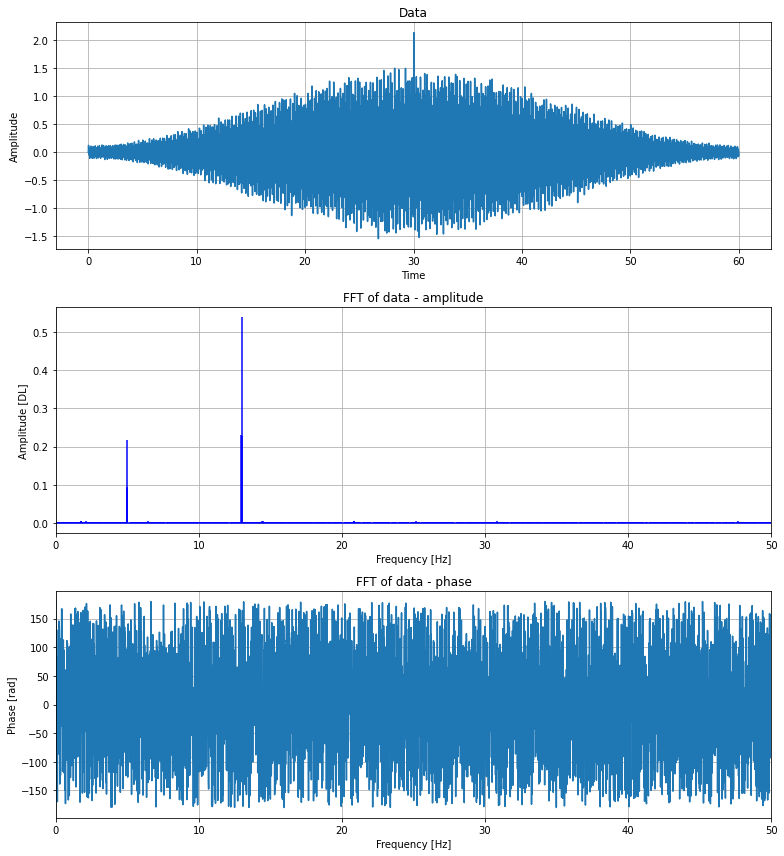

In [4]:
# generate sound wave

data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
transient_signal = sd.transients(
    trans_amp, trans_time, trans_dur, duration, sampling_rate
)
data += transient_signal
data += sd.noise(std_noise, duration, sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

Calculating crest factor and energy

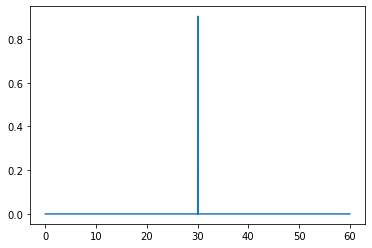

In [5]:
plt.plot(t_plot, transient_signal)
plt.show()

Wavelet transform

In [7]:
# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
wpt_df = pd.DataFrame(
    columns=[
        "node",
        "inverse",
        "fft",
        "energy",
        "kurtosis",
        "crest",
        "entropy",
        "skewness",
    ]
)

total_energy = stats.calc_energy(data)

# calculate energy, kurtosis, and crest factor of reconstructed signals
counter = 0
for node in tr_ob.get_level(level=levels, order="freq"):
    node_data = node.data  # coefficients from transform

    # calculate inverse transform
    inverse = inv.inv_dwpt(tr_ob, nodes=node.node_number)
    inverse_signal_length = len(inverse)

    # calculate fft of inverse
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )

    # calculate statistical measures
    entropy_node = stats.calc_entropy(node.energy, total_energy)
    kurtosis = stats.calc_kurtosis(node_data)
    skewness = stats.calc_skewness(node_data)
    crest = stats.calc_crest_factor(node_data)

    wpt_df.loc[counter, "node"] = node
    wpt_df.loc[counter, "inverse"] = inverse
    wpt_df.loc[counter, "fft"] = fft
    wpt_df.loc[counter, "energy"] = node.energy
    wpt_df.loc[counter, "kurtosis"] = kurtosis
    wpt_df.loc[counter, "crest"] = crest
    wpt_df.loc[counter, "entropy"] = entropy_node
    wpt_df.loc[counter, "skewness"] = skewness
    counter += 1

tr_ob.info(level=levels, order="freq")

,node number,energy,kurtosis,crest factor,skewness,frequency range
0,0,0.004492,4.747948,-0.188643,0.163623,"(0.0, 1.562e0)"
1,1,0.005362,8.161436,2.983759,-0.931524,"(1.562e0, 3.125e0)"
2,3,0.020438,3.698475,-1.618895,-0.249821,"(3.125e0, 4.688e0)"
3,2,0.836048,3.34379,-3.414279,0.006693,"(4.688e0, 6.25e0)"
4,6,0.022958,4.880524,-0.612899,0.188663,"(6.25e0, 7.812e0)"
5,7,0.004756,6.779536,0.963648,0.252019,"(7.812e0, 9.375e0)"
6,5,0.003837,5.414454,-0.161221,-0.316023,"(9.375e0, 1.094e1)"
7,4,1.84234,3.282785,-3.666471,0.009733,"(1.094e1, 1.25e1)"
8,12,3.453902,3.270042,-3.726741,-0.017687,"(1.25e1, 1.406e1)"
9,13,0.004467,6.205738,1.702267,-0.361129,"(1.406e1, 1.562e1)"


In [7]:
wpt_df

,node,inverse,fft,energy,kurtosis,crest,entropy,skewness
0,<wavelet_transform.wpt.transform_object.Node o...,"[0.01567587106122098, 0.01577079955515389, 0.0...","[(0.0001801752401306363+0j), (0.00024987703170...",0.005184,8.329093,3.160859,0.1209,0.106504
1,<wavelet_transform.wpt.transform_object.Node o...,"[0.013363031363213144, 0.013786309307169176, 0...","[(1.181439883679885e-05+0j), (1.18142344046560...",0.004882,6.531465,1.436968,0.115651,-0.517486
2,<wavelet_transform.wpt.transform_object.Node o...,"[0.017996389659807443, 0.014412162808237731, 0...","[(-4.099621667602152e-06+0j), (-4.099866425466...",0.023966,3.430272,-2.162377,0.334885,0.17141
3,<wavelet_transform.wpt.transform_object.Node o...,"[-0.007107960946853826, -0.007355697605830565,...","[(-2.5461875768958667e-05+0j), (-2.54620783188...",0.835207,3.30766,-2.79233,-6.440196,0.002864
4,<wavelet_transform.wpt.transform_object.Node o...,"[-0.002210649080301774, 0.0004266767194407632,...","[(9.126255517163589e-06+0j), (9.12630451321235...",0.022842,3.939903,-2.200361,0.325877,0.142138
5,<wavelet_transform.wpt.transform_object.Node o...,"[0.005334040264998841, 0.003391778867927882, 0...","[(1.1934203528248411e-05+0j), (1.1934239211954...",0.005374,15.955047,5.440518,0.124163,1.164381
6,<wavelet_transform.wpt.transform_object.Node o...,"[0.0038094281736860487, 0.0025329946190534615,...","[(1.4612456825699801e-06+0j), (1.4612528953583...",0.003475,5.677459,1.238047,0.089535,0.117601
7,<wavelet_transform.wpt.transform_object.Node o...,"[0.018322295274600067, 0.01846362563649884, 0....","[(-5.784434467355955e-07+0j), (-5.784514366711...",1.846791,3.292712,-3.501804,-23.189241,-0.052543
8,<wavelet_transform.wpt.transform_object.Node o...,"[-0.07113919506547842, -0.03472054712107497, 0...","[(-2.9392714763361025e-06+0j), (-2.93927136658...",3.49036,3.293936,-3.476166,-57.394009,-0.001302
9,<wavelet_transform.wpt.transform_object.Node o...,"[-0.007796288521837353, -0.0020341540465120982...","[(-3.519702979250095e-06+0j), (-3.519702953561...",0.003805,6.939712,0.977382,0.095925,0.600233


### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

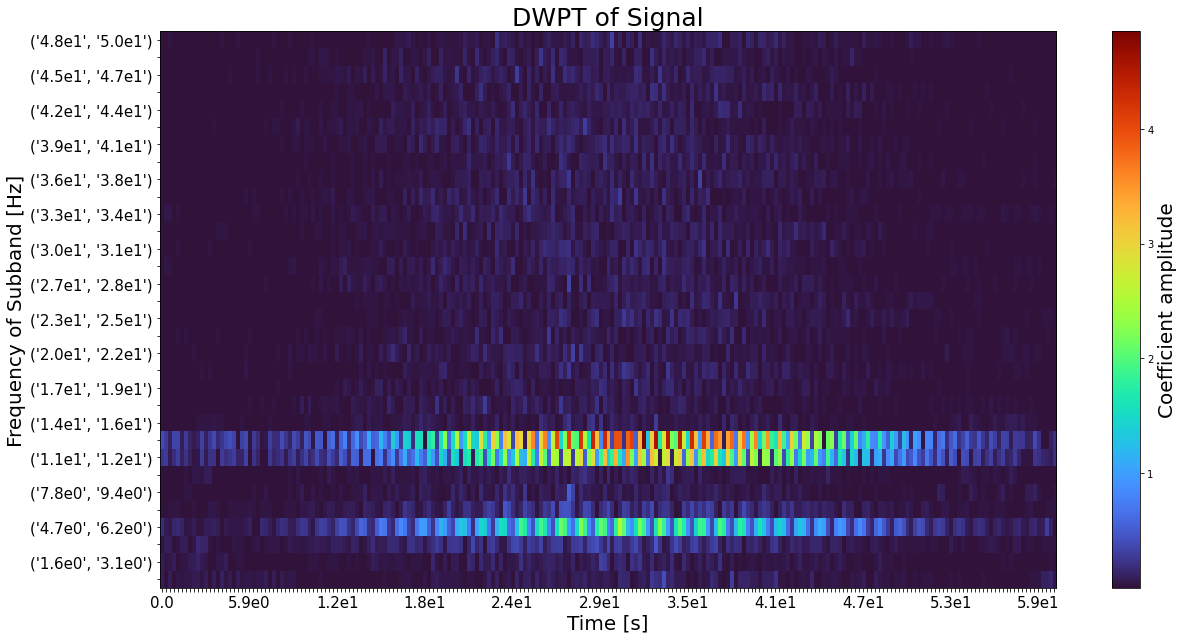

In [8]:
plot.heisenberg(tr_ob, max(t_plot))

<AxesSubplot:>

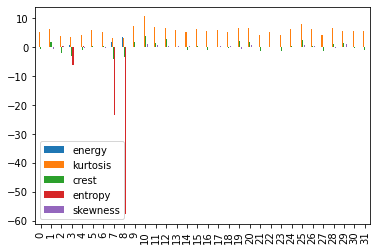

In [9]:
wpt_df.plot.bar()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

In [10]:
from sklearn import metrics
from collections import defaultdict
from time import time

evaluations = []
evaluations_std = []


def fit_and_evaluate(km, X, labels, name=None, n_runs=5):
    name = km.__class__.__name__ if name is None else name

    train_times = []
    scores = defaultdict(list)
    for seed in range(n_runs):
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)
        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, km.labels_)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X, km.labels_, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)

In [11]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
classifying_metrics = ["energy", "kurtosis", "skewness"]
data_train = wpt_df[classifying_metrics]

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 3
kmeans_params = {
    "init": "k-means++",
    "n_init": 10,
    "max_iter": 100,
    "tol": 1e-8,
    "verbose": 0,
    "algorithm": "elkan",
}

kmeans = KMeans(n_clusters=no_clusters, **kmeans_params)
data_train_predict = kmeans.fit_predict(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
print(kmeans.cluster_centers_)
print(kmeans.n_iter_)
# centers = kmeans.cluster_centers_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

[[-0.22833681 -0.17580438 -0.41805686]
 [ 3.61121486 -1.59585723 -0.45151842]
 [-0.28152614  1.03360216  1.50262065]]
2


In [12]:
data_train_predict

array([0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 2, 2, 2, 0, 0, 0, 0, 2, 0, 0, 2, 0,
       0, 0, 0, 2, 0, 0, 0, 2, 0, 0])

In [13]:
cluster_ids, cluster_sizes = np.unique(kmeans.labels_, return_counts=True)
print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print(f"cluster IDs: {cluster_ids}")

Number of elements assigned to each cluster: [23  2  7]
cluster IDs: [0 1 2]


In [14]:
fit_and_evaluate(kmeans, data_train_normalised, labels, name="test")

clustering done in 0.02 ± 0.00 s 
Homogeneity: 1.000 ± 0.000
Completeness: 1.000 ± 0.000
V-measure: 1.000 ± 0.000
Adjusted Rand-Index: 1.000 ± 0.000
Silhouette Coefficient: 0.456 ± 0.000


3 clusters:

- high energy, low kurtosis, low skewness -> harmonic
- low energy, high kurtosis, high skewness -> transient
- low energy, medium kurtosis, low skewness -> noise

### Reassigning Groups

Post-hoc reassignment of groups based on the energy and kurtosis of their clusters.

In [15]:
def assign_labels(centers, labels, sort_by=1):
    """
    assign labels to clusters. Assign the highest cluster number to the centre with
    highest energy. Then assign the rest in order of sort_by. The group numbers are reassigned
    to 1-indexed groups.

    Paramaters
    -----------
    centers: array
        array where each row is a centre of a cluster
    labels: list
        list of group assignments to reassign
    sort_by: int
        always sort out the highest energy because the harmonic can be separated
        from the rest by its much greater energy. Otherwise, sort by attribute
        number = sort_by of the centres. e.g. sort_by == 1 will sort the rest
        by kurtosis, sort_by == 2 will sort by crest factor etc.
    """
    # sort labels by energy, highest cluster energy is highest group number
    sort_by_energy = np.argsort(centers[:, 0])

    # sort rest of the labels by kurtosis
    sort_rest = np.argsort(centers[:, sort_by])

    sort_rest = np.delete(
        sort_rest,  # delete highest energy group form kurtosis
        np.where(sort_rest == sort_by_energy[-1])[0][0],
        axis=0,
    )
    sort_rest = np.append(sort_rest, None)

    # create mapping from old cluster labels to new cluster labels
    mapping = {}
    for new_label, index in enumerate(zip(sort_by_energy, sort_rest)):
        if new_label == len(sort_by_energy) - 1:  # highest group no has highest energy
            mapping[index[0]] = new_label + 1
        else:
            mapping[index[1]] = (
                new_label + 1
            )  # other group numbers are arranged by kurtosis

    # update labels
    reassigned_labels = [mapping[label] for label in labels]
    return reassigned_labels

In [16]:
reassigned_labels = assign_labels(centers, labels)

### Plot result

Plot the assigned group against the frequency of the node. 

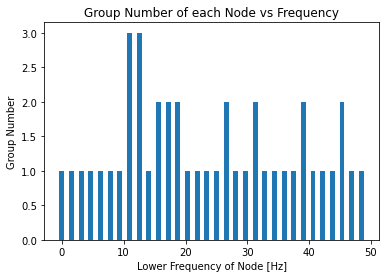

In [17]:
# plot regular k-means
plt.bar([node.frequency_range[0] for node in wpt_df["node"]], reassigned_labels)
plt.title("Group Number of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Group Number")
plt.show()

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [18]:
# apply PCA to training data
pca = PCA(n_components=data_train.shape[1])
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters, **kmeans_params)
data_train_predict_pca = kmeans_pca.fit_predict(data_pca)

# convert centres back to regular feature space (energy, kurtosis, crest, etc.)
labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(
    pca.inverse_transform(kmeans_pca.cluster_centers_)
)
reassigned_pca_labels = assign_labels(centers_pca, labels_pca)

### Plot PCA result

The group number vs frequency for each node is plotted again after PCA is applied.

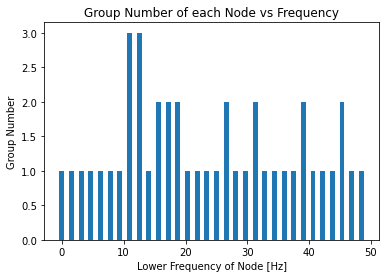

Eigenvectors:
energy, kurtosis, skewness
[[ 0.53 -0.67 -0.52]
 [ 0.7  -0.01  0.72]
 [ 0.48  0.74 -0.46]]
Eigenvalues: [1.75 0.9  0.45]


In [19]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node in wpt_df["node"]]
plt.bar([node.frequency_range[0] for node in wpt_df["node"]], reassigned_pca_labels)
plt.tick_params
plt.title("Group Number of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Group Number")
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print("energy, kurtosis, skewness")
print(np.round(eigenvectors, 2))

print("Eigenvalues:", np.round(eigenvalues, 2))

### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

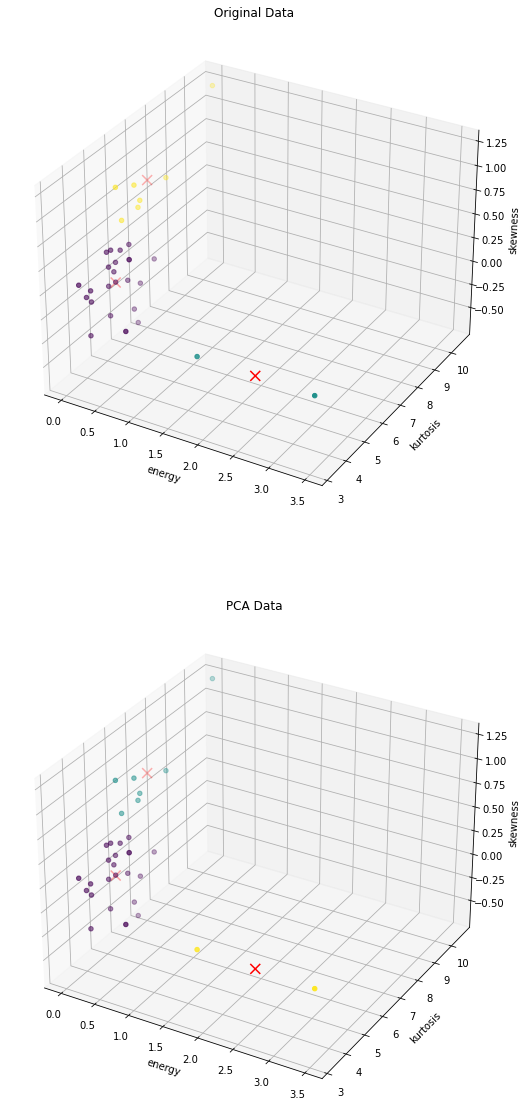

In [20]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={"projection": "3d"})

titles = ["Original Data", "PCA Data"]

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap("Set1")
    if i == 0:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers
        labels_scatter = reassigned_labels
        color_map_labels = data_train_predict
    else:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers_pca
        labels_scatter = labels_pca
        color_map_labels = data_train_predict_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        # c=[cmap(label) for label in labels_scatter],
        c=color_map_labels,
    )
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c="red",
        marker="x",
        s=100,
    )

    ax.set_xlabel(data_train.columns[0])
    ax.set_ylabel(data_train.columns[1])
    ax.set_zlabel(data_train.columns[2])
    ax.set_title(titles[i])

plt.show()

### Results

Plotting the reconstructed waves at each node alongside their assigned group number.

In [21]:
def plot_reconstructions(wpt_recon_df, group=None):
    for i in range(wpt_recon_df.shape[0]):  # highest energy, kurtosis, etc.
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = wpt_recon_df["node"].values.tolist()[i].frequency_range
        ax[0].plot(
            t_plot,
            wpt_recon_df["inverse"].values.tolist()[i],
        )
        title = f"Reconstructed sub-band [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed sub-band [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(wpt_recon_df["fft"].values.tolist()[i]),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed sub-band")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()
        print(wpt_recon_df.iloc[i, 3:])

Change to group=reassign_pca_labels to display the groups assigned using PCA

In [22]:
# plot_reconstructions(wpt_df, group=reassigned_labels)
# plot_reconstructions(wpt_recon_df, group=reassigned_pca_labels)

In [23]:
THR_Factor = 0.1
harmonics_data = wpt_df[
    data_train["energy"] > THR_Factor * np.max(data_train["energy"])
]
harmonics_data = harmonics_data.sort_values(by="energy", ascending=False)

In [24]:
transient_data = wpt_df[
    (data_train["kurtosis"] > THR_Factor * np.max(data_train["kurtosis"]))
    & (data_train["skewness"] > THR_Factor * np.max(data_train["skewness"]))
]
harmonics_data = harmonics_data.sort_values(by="kurtosis", ascending=False)

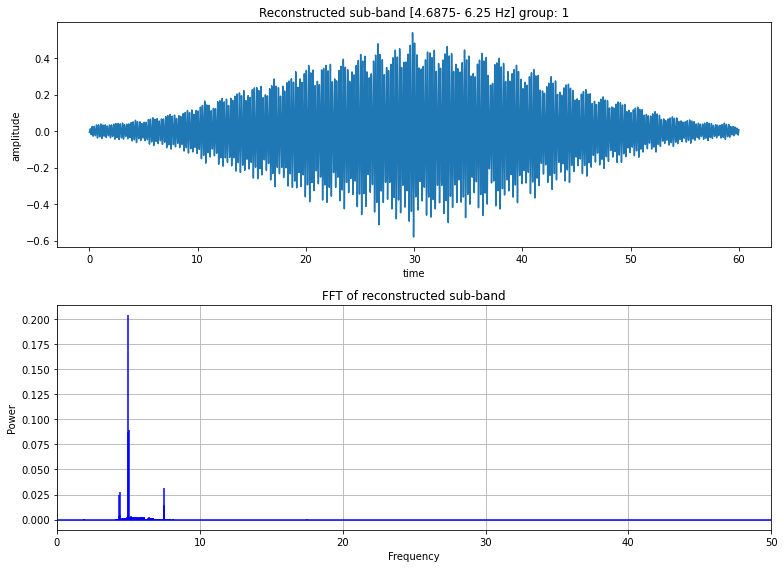

energy       0.80629
kurtosis    3.358125
crest      -3.168374
entropy    -6.115079
skewness    0.002731
Name: 3, dtype: object


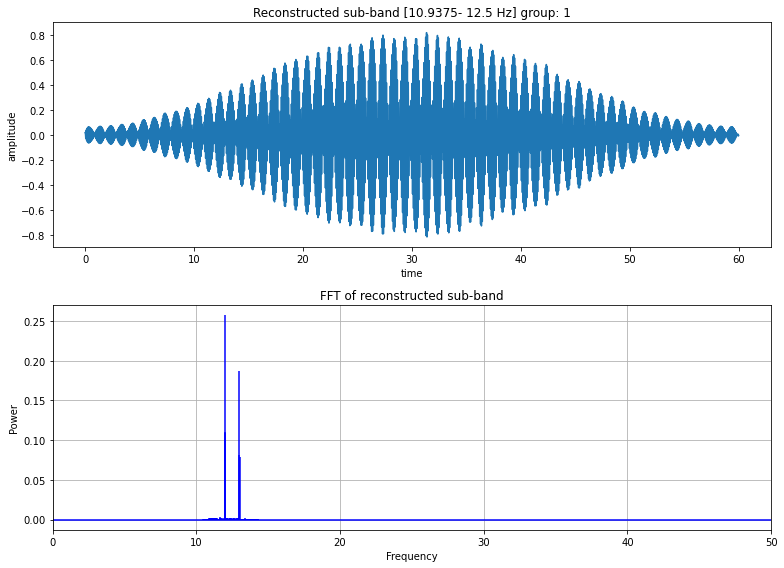

energy       1.849298
kurtosis      3.28837
crest       -4.115091
entropy    -23.460551
skewness    -0.011333
Name: 7, dtype: object


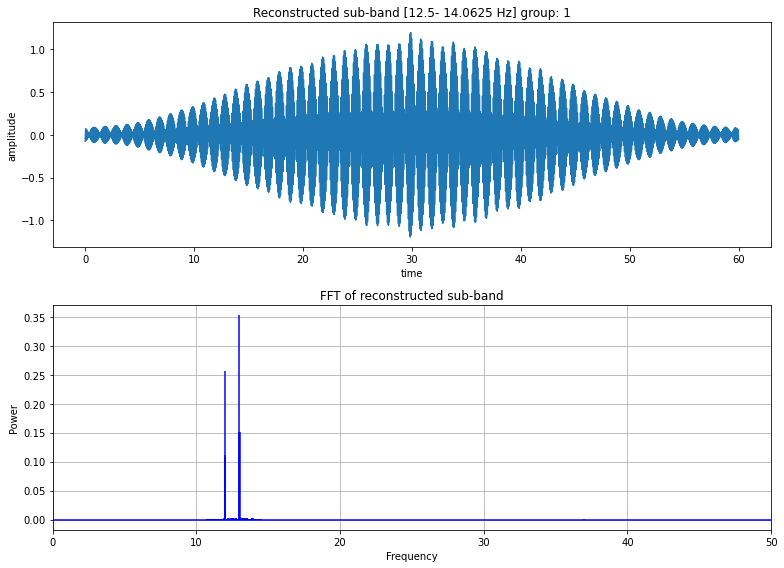

energy       3.481976
kurtosis     3.273383
crest        -3.52953
entropy    -57.715167
skewness    -0.033931
Name: 8, dtype: object


In [25]:
plot_reconstructions(harmonics_data, group=reassigned_labels)

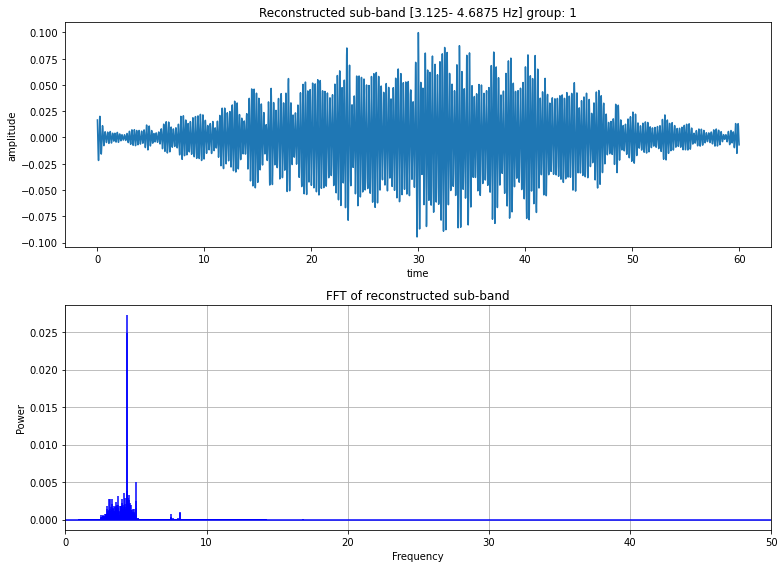

energy      0.022581
kurtosis    3.695142
crest      -1.903389
entropy     0.324943
skewness    0.252559
Name: 2, dtype: object


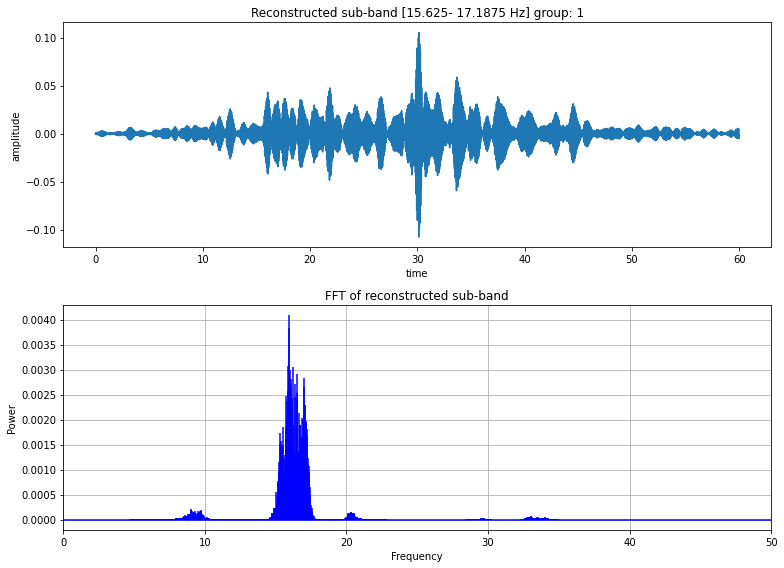

energy       0.004776
kurtosis    10.585821
crest        3.867127
entropy      0.114326
skewness     1.224594
Name: 10, dtype: object


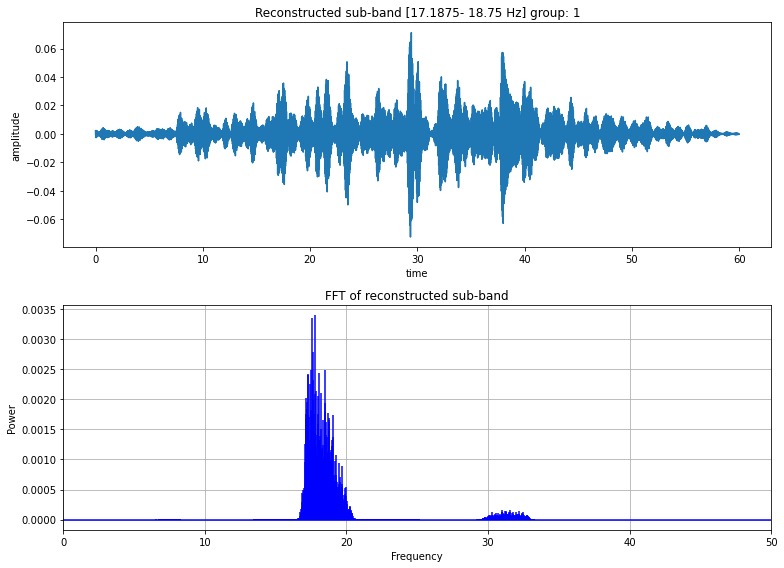

energy      0.003442
kurtosis    6.782945
crest       1.593093
entropy     0.089324
skewness    0.611207
Name: 11, dtype: object


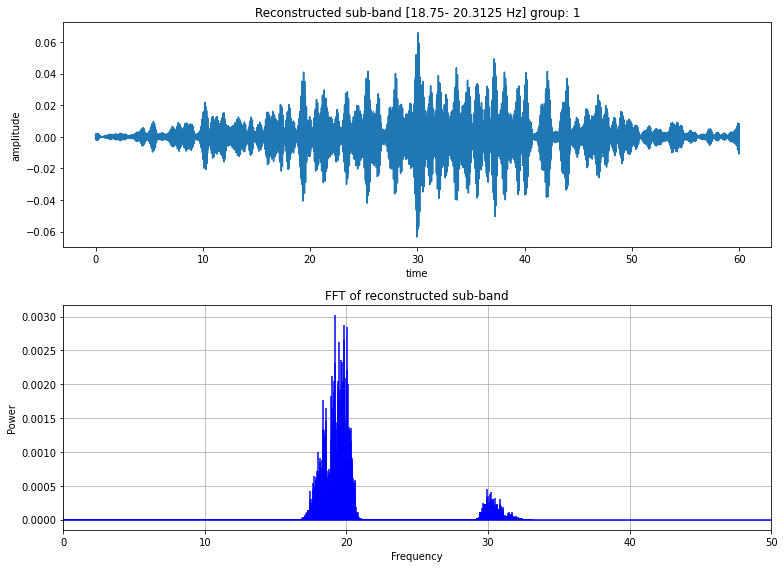

energy      0.003282
kurtosis    6.684156
crest        2.69789
entropy     0.086141
skewness     0.55407
Name: 12, dtype: object


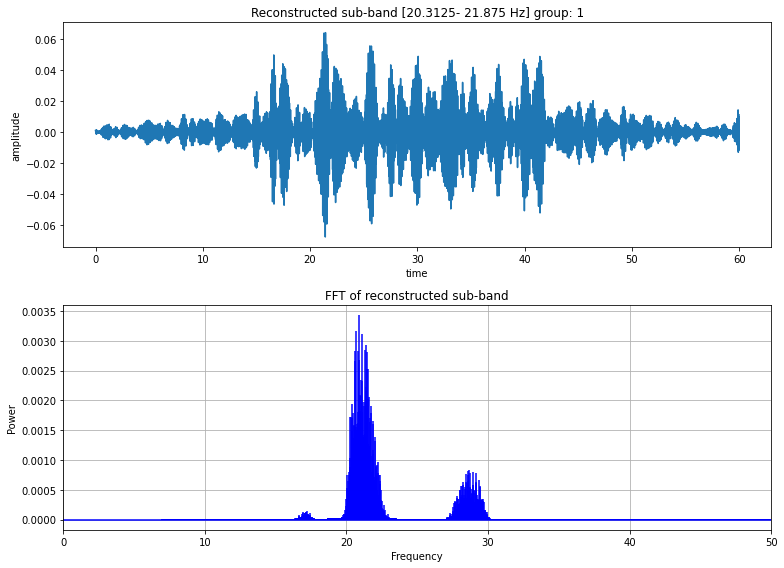

energy      0.004077
kurtosis    5.756897
crest        0.10708
entropy     0.101563
skewness    0.259571
Name: 13, dtype: object


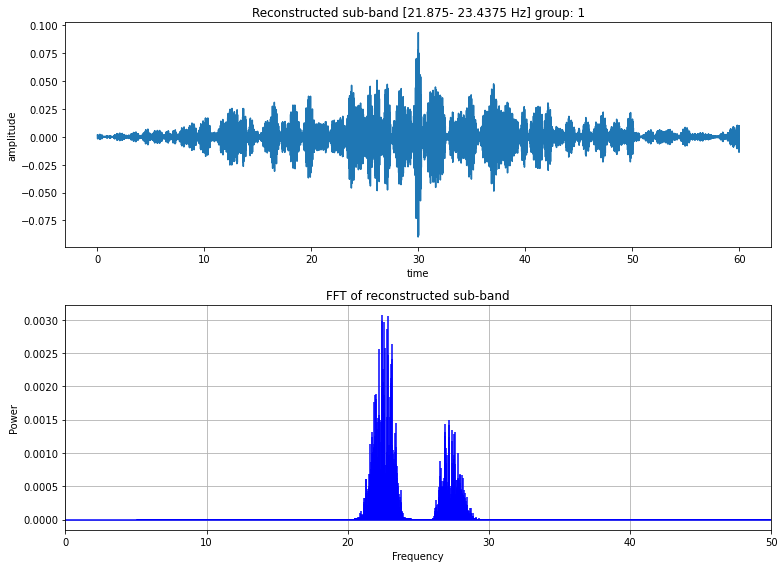

energy      0.003607
kurtosis    5.101078
crest      -0.875537
entropy     0.092569
skewness    0.349194
Name: 14, dtype: object


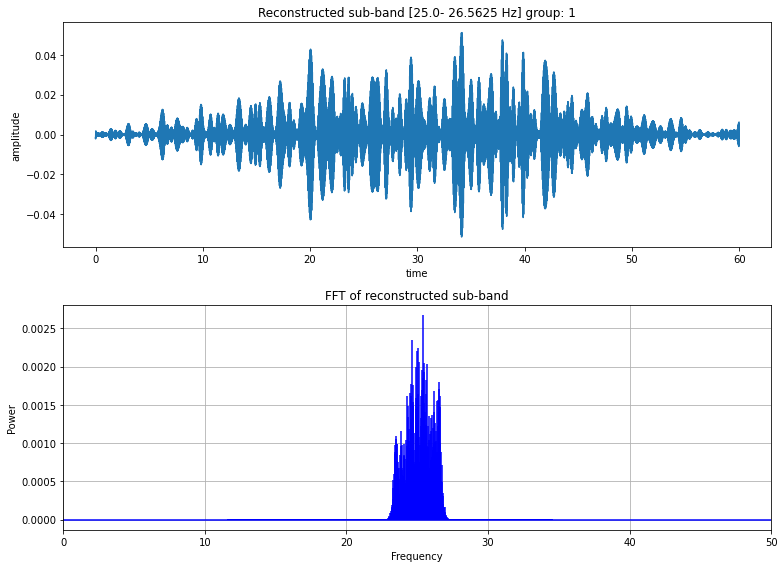

energy      0.003121
kurtosis    5.516858
crest      -0.921853
entropy      0.08287
skewness    0.172304
Name: 16, dtype: object


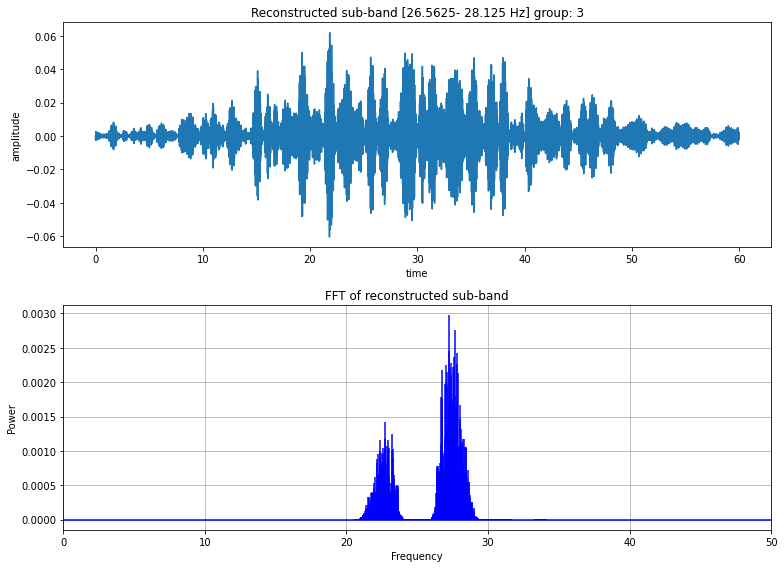

energy      0.003396
kurtosis    5.871154
crest       0.109713
entropy     0.088416
skewness    0.551444
Name: 17, dtype: object


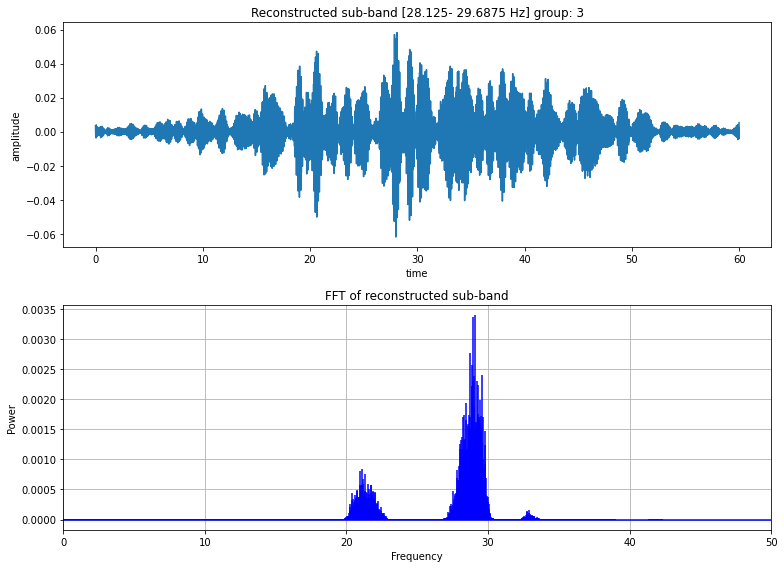

energy      0.003132
kurtosis    5.304083
crest      -0.343033
entropy     0.083096
skewness    0.336116
Name: 18, dtype: object


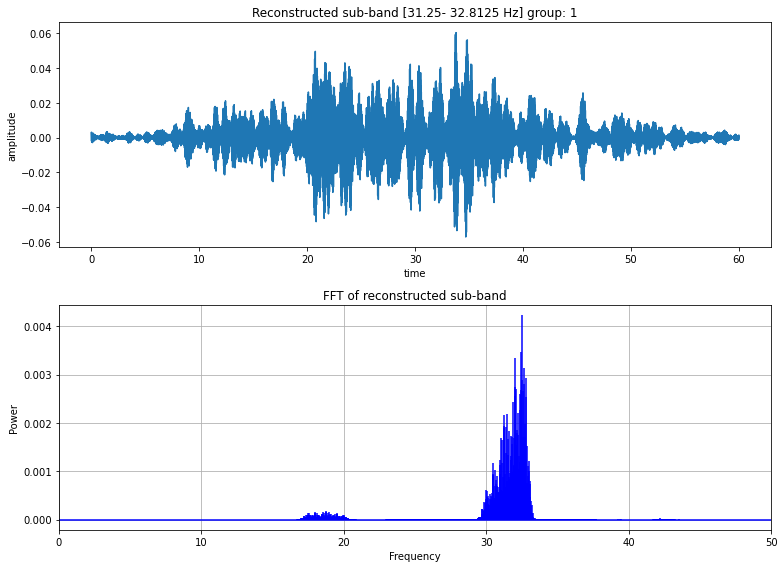

energy       0.00396
kurtosis    6.514665
crest       1.754531
entropy     0.099355
skewness    0.812691
Name: 20, dtype: object


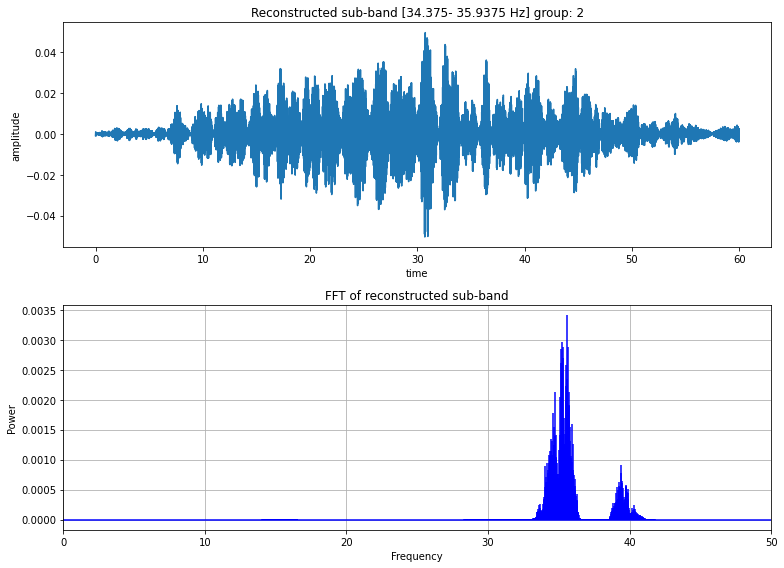

energy      0.003063
kurtosis    5.178277
crest      -0.105297
entropy     0.081678
skewness     0.18024
Name: 22, dtype: object


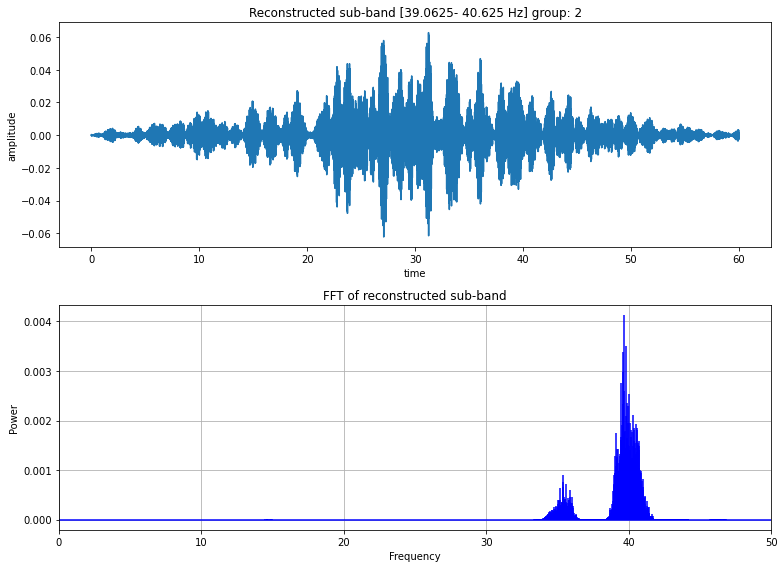

energy       0.00361
kurtosis    8.109962
crest       2.333938
entropy     0.092629
skewness      0.6358
Name: 25, dtype: object


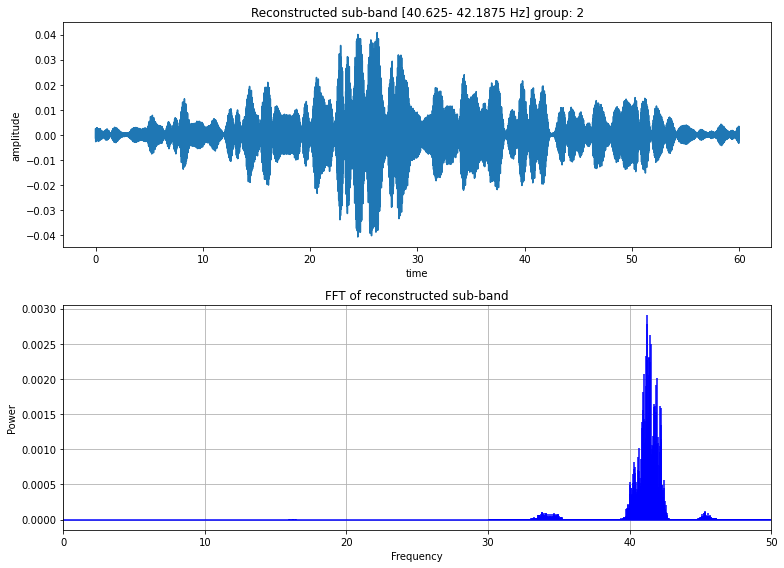

energy      0.002197
kurtosis    6.193606
crest        0.38368
entropy     0.063087
skewness    0.245535
Name: 26, dtype: object


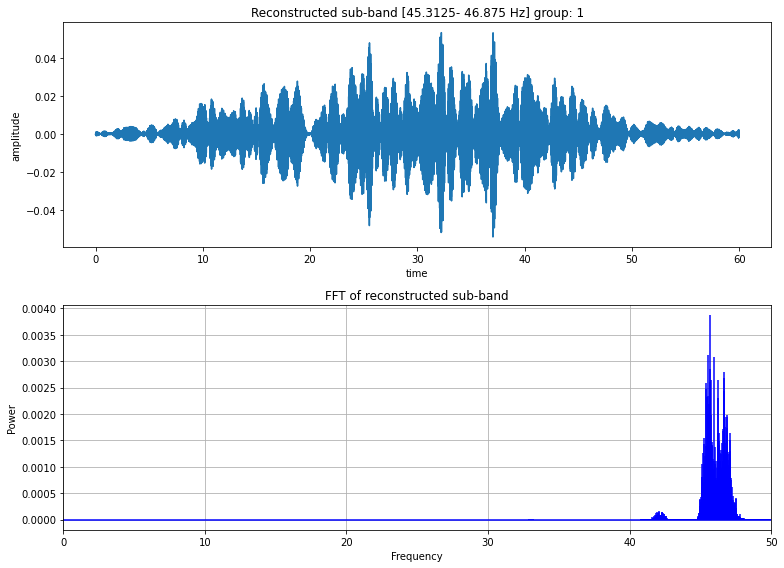

energy      0.003474
kurtosis    5.622816
crest       1.386557
entropy     0.089957
skewness    0.932337
Name: 29, dtype: object


In [26]:
plot_reconstructions(transient_data, group=reassigned_labels)

In [27]:
harmonics_data["node"].values.tolist()[0].frequency_range

(4.6875, 6.25)

<AxesSubplot:>

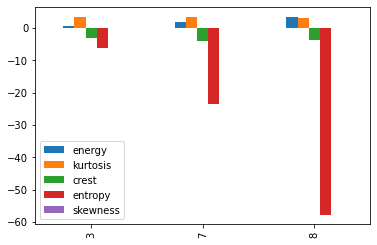

In [28]:
harmonics_data.plot.bar()

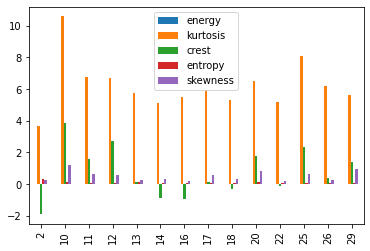

In [29]:
transient_data.plot.bar()
plt.show()